In [120]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve
)

import warnings
warnings.filterwarnings("ignore")

In [121]:
from google.colab import files

uploaded = files.upload()

Saving Telco-Customer-Churn.csv to Telco-Customer-Churn (1).csv


In [122]:
df = pd.read_csv("Telco-Customer-Churn.csv")

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [123]:
print("Dataset Shape:", df.shape)

Dataset Shape: (7043, 21)


In [124]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [125]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [126]:
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [127]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_percentage[missing_percentage > 0]

,0


In [128]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [129]:
print("Duplicate customer IDs:", df["customerID"].duplicated().sum())

Duplicate customer IDs: 0


In [130]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [131]:
df.describe(include="object")

,customerID,gender,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,TotalCharges,Churn
count,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043
unique,7043,2,2,2,2,3,3,3,3,3,3,3,3,3,2,4,6531,2
top,3186-AJIEK,Male,No,No,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,,No
freq,1,3555,3641,4933,6361,3390,3096,3498,3088,3095,3473,2810,2785,3875,4171,2365,11,5174


In [132]:
df["Churn"].value_counts()

,count
Churn,
No,5174
Yes,1869


In [133]:
df["Churn"].value_counts(normalize=True) * 100

,proportion
Churn,
No,73.463013
Yes,26.536987


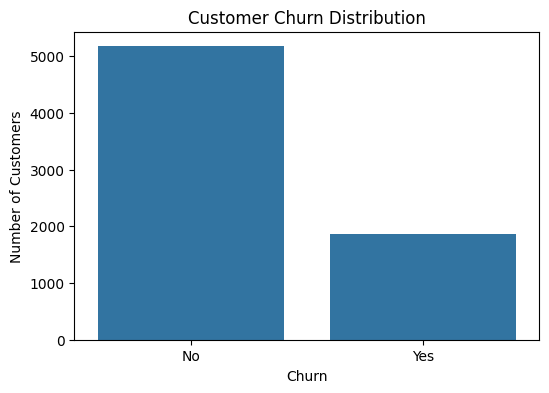

In [134]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.show()

In [135]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

In [136]:
df["TotalCharges"].isnull().sum()

np.int64(11)

In [137]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)

In [138]:
X = df.drop(columns=["Churn", "customerID"])

In [139]:
y = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

In [140]:
numeric_features = [
    "SeniorCitizen",
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

In [141]:
categorical_features = [
    "gender",
    "Partner",
    "Dependents",
    "PhoneService",
    "MultipleLines",
    "InternetService",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies",
    "Contract",
    "PaperlessBilling",
    "PaymentMethod"
]

In [142]:
X = df.drop(columns=["Churn", "customerID"])

y = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (5634, 19)
Testing data: (1409, 19)


In [143]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numeric_features
        ),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            categorical_features
        )
    ]
)

In [144]:
logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(
            max_iter=1000
        ))
    ]
)

In [145]:
logistic_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['SeniorCitizen', 'tenure',
                                                   'MonthlyCharges',
                                                   'TotalCharges']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['gender', 'Partner',
                                                   'Dependents', 'PhoneService',
                                                   'MultipleLines',
                                                   'InternetService',
                                                   'OnlineSecurity',
                                                   'OnlineBackup',
                                                   'DeviceProtection',
                                                   'TechSupport', 'StreamingTV',
                                                   'StreamingMovies',
                                                   'Contract',
                                                   'PaperlessBilling',
                                                   'PaymentMethod'])])),
                ('classifier', LogisticRegression(max_iter=1000))])

In [146]:
y_pred = logistic_model.predict(X_test)

In [147]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1)

Accuracy : 0.8055358410220014
Precision: 0.6572327044025157
Recall   : 0.5588235294117647
F1 Score : 0.6040462427745664


In [148]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1035
           1       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



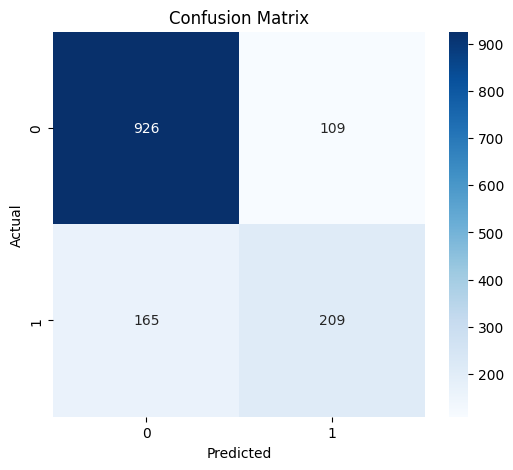

In [149]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [150]:
random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            random_state=42,
            class_weight="balanced"
        ))
    ]
)

In [151]:
random_forest_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['SeniorCitizen', 'tenure',
                                                   'MonthlyCharges',
                                                   'TotalCharges']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['gender', 'Partner',
                                                   'Dependents', 'PhoneService',
                                                   'MultipleLines',
                                                   'InternetService',
                                                   'OnlineSecurity',
                                                   'OnlineBackup',
                                                   'DeviceProtection',
                                                   'TechSupport', 'StreamingTV',
                                                   'StreamingMovies',
                                                   'Contract',
                                                   'PaperlessBilling',
                                                   'PaymentMethod'])])),
                ('classifier',
                 RandomForestClassifier(class_weight='balanced',
                                        n_estimators=200, random_state=42))])

In [152]:
rf_pred = random_forest_model.predict(X_test)

In [153]:
print("Accuracy :", accuracy_score(y_test, rf_pred))
print("Precision:", precision_score(y_test, rf_pred))
print("Recall   :", recall_score(y_test, rf_pred))
print("F1 Score :", f1_score(y_test, rf_pred))

Accuracy : 0.7828246983676366
Precision: 0.6188811188811189
Recall   : 0.4732620320855615
F1 Score : 0.5363636363636364


In [154]:
logistic_probability = logistic_model.predict_proba(X_test)[:, 1]

logistic_auc = roc_auc_score(
    y_test,
    logistic_probability
)

print("Logistic Regression ROC-AUC:", logistic_auc)

Logistic Regression ROC-AUC: 0.8421349040274871


In [155]:
rf_probability = random_forest_model.predict_proba(X_test)[:, 1]

rf_auc = roc_auc_score(
    y_test,
    rf_probability
)

print("Random Forest ROC-AUC:", rf_auc)

Random Forest ROC-AUC: 0.823214239582526


In [156]:
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, rf_pred)
    ],
    "Precision": [
        precision_score(y_test, y_pred),
        precision_score(y_test, rf_pred)
    ],
    "Recall": [
        recall_score(y_test, y_pred),
        recall_score(y_test, rf_pred)
    ],
    "F1 Score": [
        f1_score(y_test, y_pred),
        f1_score(y_test, rf_pred)
    ],
    "ROC-AUC": [
        logistic_auc,
        rf_auc
    ]
})

results

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.805536,0.657233,0.558824,0.604046,0.842135
1,Random Forest,0.782825,0.618881,0.473262,0.536364,0.823214


In [157]:
probability = random_forest_model.predict_proba(X_test)[:, 1]

In [158]:
def risk_level(probability):

    if probability < 0.30:
        return "Low"

    elif probability < 0.60:
        return "Medium"

    else:
        return "High"

In [159]:
risk_levels = [
    risk_level(prob)
    for prob in probability
]

In [160]:
risk_results = X_test.copy()

risk_results["Actual_Churn"] = y_test.values
risk_results["Churn_Probability"] = probability
risk_results["Risk_Level"] = risk_levels

risk_results.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Actual_Churn,Churn_Probability,Risk_Level
437,Male,0,Yes,Yes,72,Yes,Yes,Fiber optic,Yes,Yes,...,Yes,Yes,Two year,Yes,Credit card (automatic),114.05,8468.20,0,0.000,Low
2280,Female,1,No,No,8,Yes,Yes,Fiber optic,No,No,...,Yes,Yes,Month-to-month,Yes,Credit card (automatic),100.15,908.55,0,0.705,High
2235,Female,0,Yes,Yes,41,Yes,Yes,DSL,Yes,Yes,...,Yes,No,One year,Yes,Credit card (automatic),78.35,3211.20,0,0.075,Low
4460,Male,0,Yes,No,18,Yes,No,Fiber optic,No,No,...,No,No,Month-to-month,No,Electronic check,78.20,1468.75,0,0.290,Low
3761,Female,0,Yes,No,72,Yes,Yes,DSL,Yes,Yes,...,Yes,Yes,Two year,Yes,Credit card (automatic),82.65,5919.35,0,0.005,Low


In [161]:
customer = df.iloc[[0]].drop(
    columns=["Churn", "customerID"]
)

customer

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85


In [162]:
prediction = random_forest_model.predict(customer)[0]

probability = random_forest_model.predict_proba(customer)[0][1]

print("Prediction:", prediction)
print("Churn Probability:", probability)

Prediction: 0
Churn Probability: 0.225


In [163]:
risk = risk_level(probability)

print("Risk Level:", risk)

Risk Level: Low


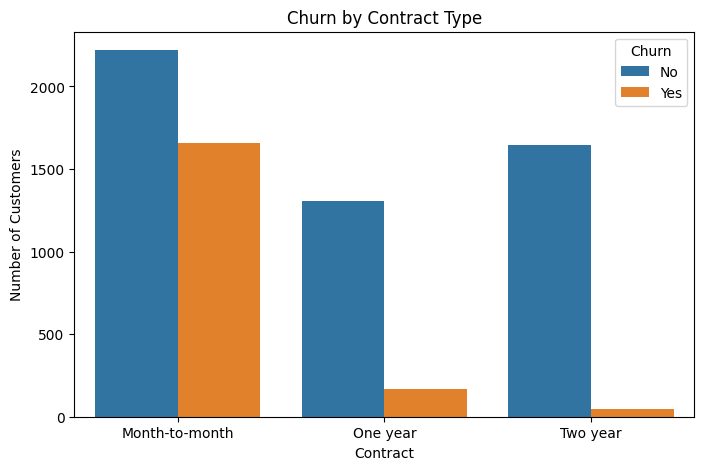

In [164]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Contract",
    hue="Churn"
)

plt.title("Churn by Contract Type")
plt.xlabel("Contract")
plt.ylabel("Number of Customers")

plt.show()

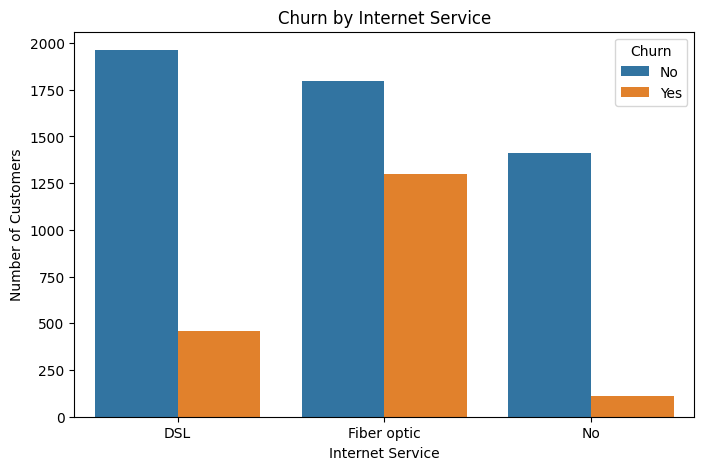

In [165]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="InternetService",
    hue="Churn"
)

plt.title("Churn by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Number of Customers")

plt.show()

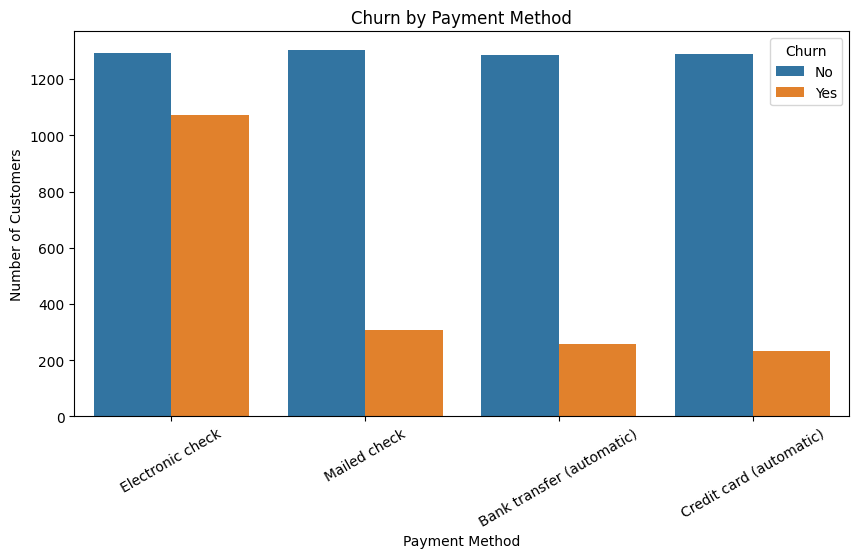

In [166]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="PaymentMethod",
    hue="Churn"
)

plt.xticks(rotation=30)

plt.title("Churn by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Number of Customers")

plt.show()

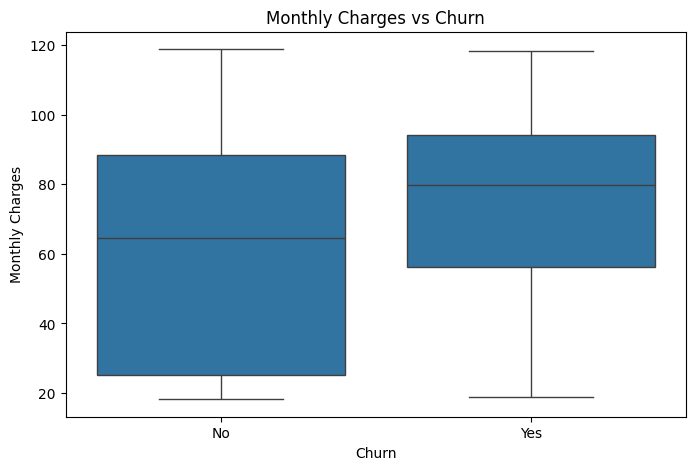

In [167]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("Monthly Charges vs Churn")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")

plt.show()

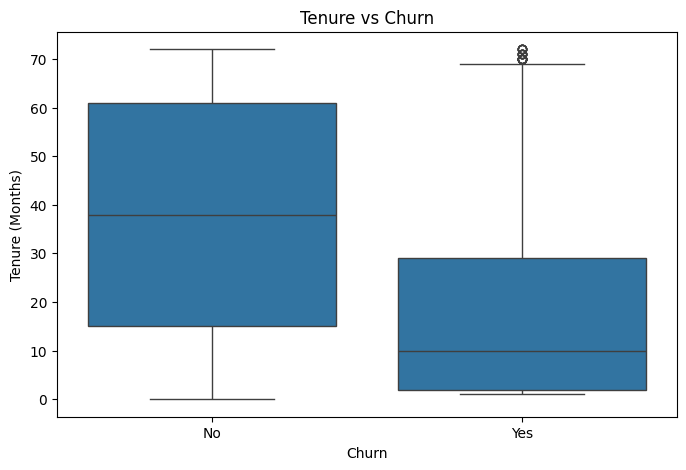

In [168]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="tenure"
)

plt.title("Tenure vs Churn")
plt.xlabel("Churn")
plt.ylabel("Tenure (Months)")

plt.show()

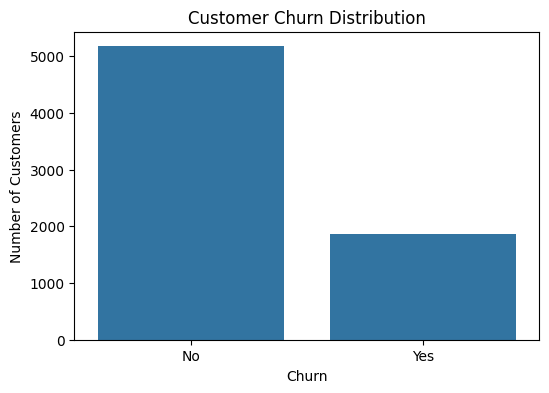

In [169]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.show()

In [170]:
churn_percentage = df["Churn"].value_counts(normalize=True) * 100

print(churn_percentage)

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


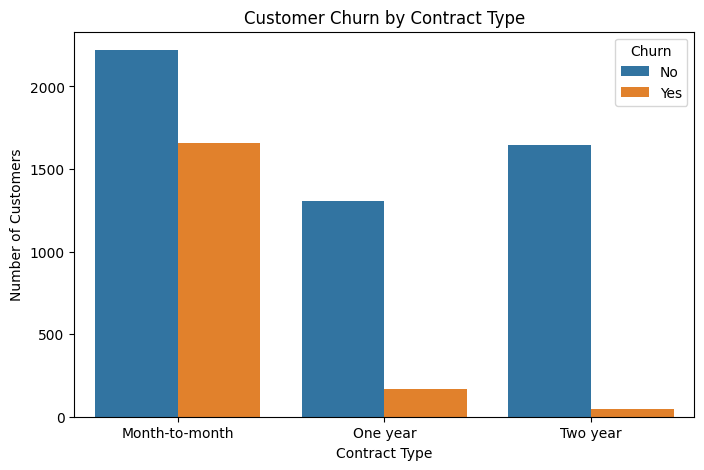

In [171]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Contract",
    hue="Churn"
)

plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")

plt.show()

In [172]:
contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

contract_churn

Churn,No,Yes
Contract,,
Month-to-month,57.290323,42.709677
One year,88.730482,11.269518
Two year,97.168142,2.831858


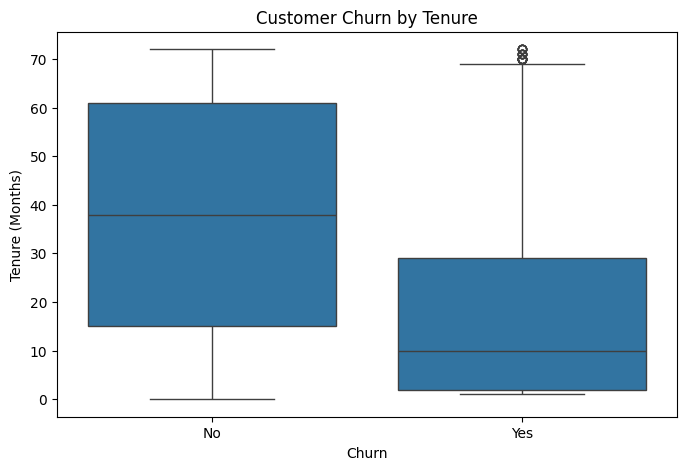

In [173]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="tenure"
)

plt.title("Customer Churn by Tenure")
plt.xlabel("Churn")
plt.ylabel("Tenure (Months)")

plt.show()

In [174]:
df.groupby("Churn")["tenure"].describe()

,count,mean,std,min,25%,50%,75%,max
Churn,,,,,,,,
No,5174.0,37.569965,24.113777,0.0,15.0,38.0,61.0,72.0
Yes,1869.0,17.979133,19.531123,1.0,2.0,10.0,29.0,72.0


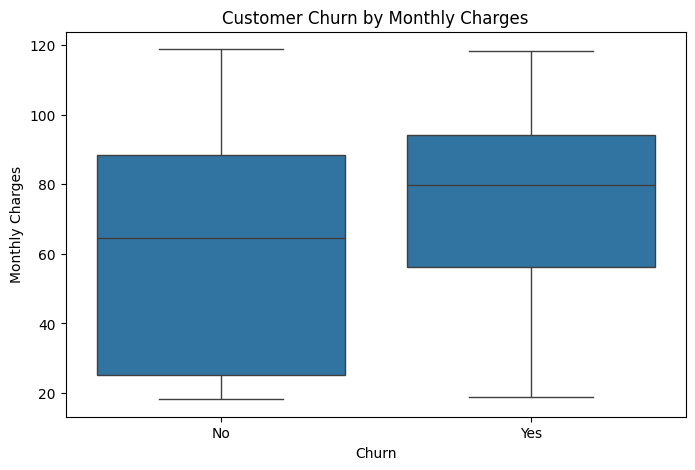

In [175]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("Customer Churn by Monthly Charges")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")

plt.show()

In [176]:
df.groupby("Churn")["MonthlyCharges"].describe()

,count,mean,std,min,25%,50%,75%,max
Churn,,,,,,,,
No,5174.0,61.265124,31.092648,18.25,25.10,64.425,88.4,118.75
Yes,1869.0,74.441332,24.666053,18.85,56.15,79.650,94.2,118.35


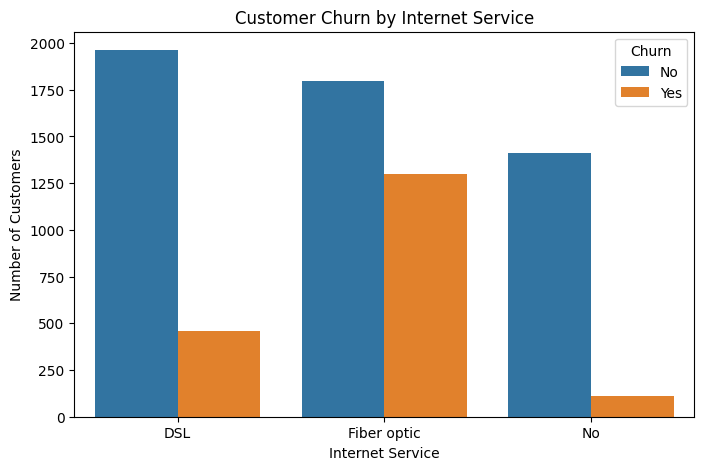

In [177]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="InternetService",
    hue="Churn"
)

plt.title("Customer Churn by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Number of Customers")

plt.show()

In [178]:
internet_churn = pd.crosstab(
    df["InternetService"],
    df["Churn"],
    normalize="index"
) * 100

internet_churn

Churn,No,Yes
InternetService,,
DSL,81.040892,18.959108
Fiber optic,58.107235,41.892765
No,92.595020,7.404980


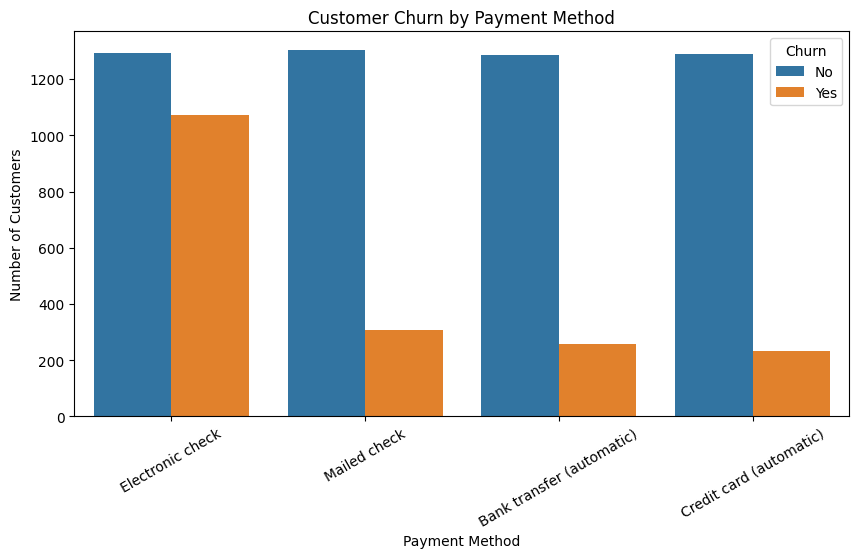

In [179]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="PaymentMethod",
    hue="Churn"
)

plt.title("Customer Churn by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Number of Customers")

plt.xticks(rotation=30)

plt.show()

In [180]:
payment_churn = pd.crosstab(
    df["PaymentMethod"],
    df["Churn"],
    normalize="index"
) * 100

payment_churn

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.290155,16.709845
Credit card (automatic),84.756899,15.243101
Electronic check,54.714588,45.285412
Mailed check,80.893300,19.106700


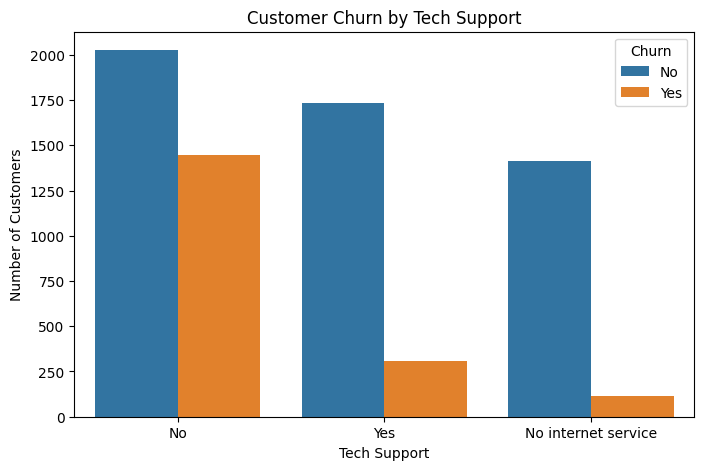

In [181]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="TechSupport",
    hue="Churn"
)

plt.title("Customer Churn by Tech Support")
plt.xlabel("Tech Support")
plt.ylabel("Number of Customers")

plt.show()

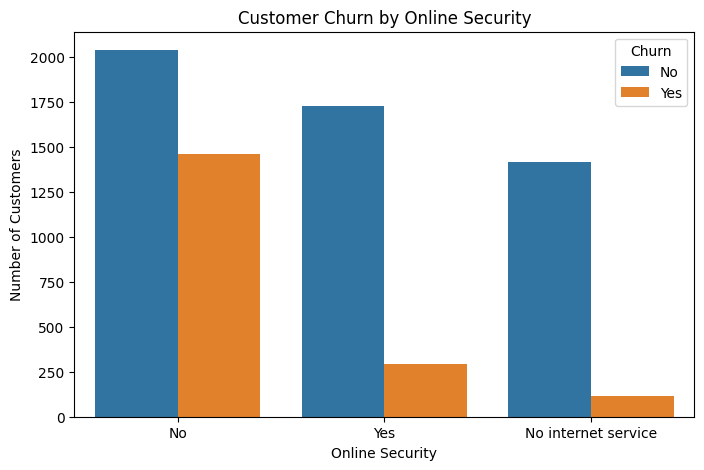

In [182]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="OnlineSecurity",
    hue="Churn"
)

plt.title("Customer Churn by Online Security")
plt.xlabel("Online Security")
plt.ylabel("Number of Customers")

plt.show()

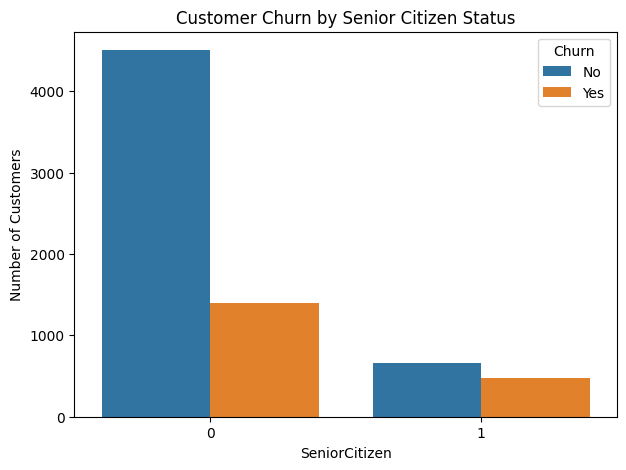

In [183]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="SeniorCitizen",
    hue="Churn"
)

plt.title("Customer Churn by Senior Citizen Status")
plt.xlabel("SeniorCitizen")
plt.ylabel("Number of Customers")

plt.show()

In [184]:
categorical_columns = [
    "gender",
    "Partner",
    "Dependents",
    "PhoneService",
    "MultipleLines",
    "InternetService",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies",
    "Contract",
    "PaperlessBilling",
    "PaymentMethod"
]

In [185]:
for column in categorical_columns:
    print("\n", "=" * 50)
    print(column)

    result = pd.crosstab(
        df[column],
        df["Churn"],
        normalize="index"
    ) * 100

    print(result.round(2))


gender
Churn      No    Yes
gender              
Female  73.08  26.92
Male    73.84  26.16

Partner
Churn       No    Yes
Partner              
No       67.04  32.96
Yes      80.34  19.66

Dependents
Churn          No    Yes
Dependents              
No          68.72  31.28
Yes         84.55  15.45

PhoneService
Churn            No    Yes
PhoneService              
No            75.07  24.93
Yes           73.29  26.71

MultipleLines
Churn                No    Yes
MultipleLines                 
No                74.96  25.04
No phone service  75.07  24.93
Yes               71.39  28.61

InternetService
Churn               No    Yes
InternetService              
DSL              81.04  18.96
Fiber optic      58.11  41.89
No               92.60   7.40

OnlineSecurity
Churn                   No    Yes
OnlineSecurity                   
No                   58.23  41.77
No internet service  92.60   7.40
Yes                  85.39  14.61

OnlineBackup
Churn                   No    Yes
Online

In [186]:
numeric_df = df[
    [
        "SeniorCitizen",
        "tenure",
        "MonthlyCharges",
        "TotalCharges"
    ]
]

In [187]:
correlation = numeric_df.corr()

correlation

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
SeniorCitizen,1.000000,0.016567,0.220173,0.103006
tenure,0.016567,1.000000,0.247900,0.826178
MonthlyCharges,0.220173,0.247900,1.000000,0.651174
TotalCharges,0.103006,0.826178,0.651174,1.000000


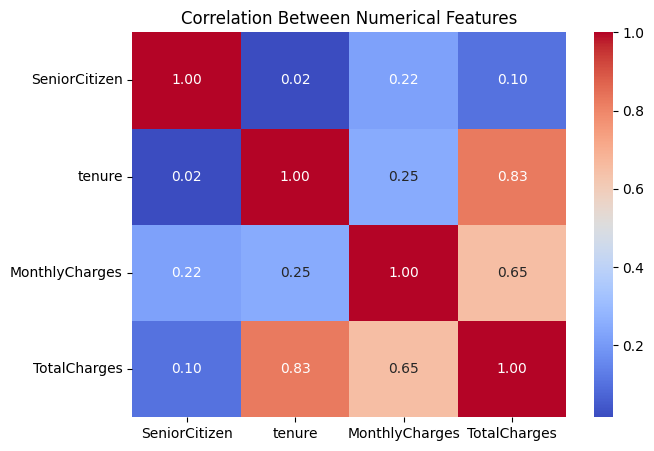

In [188]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Correlation Between Numerical Features")

plt.show()

In [189]:
df.groupby("Churn")[
    [
        "SeniorCitizen",
        "tenure",
        "MonthlyCharges",
        "TotalCharges"
    ]
].mean()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
Churn,,,,
No,0.128721,37.569965,61.265124,2549.911442
Yes,0.254682,17.979133,74.441332,1531.796094


In [190]:
X = df.drop(columns=["Churn", "customerID"])

y = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (7043, 19)
Target shape: (7043,)


In [191]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (5634, 19)
Testing data: (1409, 19)


In [192]:
numeric_features = [
    "SeniorCitizen",
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

categorical_features = [
    "gender",
    "Partner",
    "Dependents",
    "PhoneService",
    "MultipleLines",
    "InternetService",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies",
    "Contract",
    "PaperlessBilling",
    "PaymentMethod"
]

In [193]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numeric_features
        ),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ]
)

In [194]:
logistic_model_balanced = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(
            max_iter=2000,
            class_weight="balanced"
        ))
    ]
)

In [195]:
logistic_model_balanced.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['SeniorCitizen', 'tenure',
                                                   'MonthlyCharges',
                                                   'TotalCharges']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['gender', 'Partner',
                                                   'Dependents', 'PhoneService',
                                                   'MultipleLines',
                                                   'InternetService',
                                                   'OnlineSecurity',
                                                   'OnlineBackup',
                                                   'DeviceProtection',
                                                   'TechSupport', 'StreamingTV',
                                                   'StreamingMovies',
                                                   'Contract',
                                                   'PaperlessBilling',
                                                   'PaymentMethod'])])),
                ('classifier',
                 LogisticRegression(class_weight='balanced', max_iter=2000))])

In [196]:
logistic_balanced_pred = logistic_model_balanced.predict(X_test)

In [197]:
print("Accuracy :", accuracy_score(y_test, logistic_balanced_pred))
print("Precision:", precision_score(y_test, logistic_balanced_pred))
print("Recall   :", recall_score(y_test, logistic_balanced_pred))
print("F1 Score :", f1_score(y_test, logistic_balanced_pred))

Accuracy : 0.7381121362668559
Precision: 0.504302925989673
Recall   : 0.7834224598930482
F1 Score : 0.6136125654450262


In [198]:
print(
    classification_report(
        y_test,
        logistic_balanced_pred
    )
)

              precision    recall  f1-score   support

           0       0.90      0.72      0.80      1035
           1       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409



In [199]:
logistic_balanced_probability = (
    logistic_model_balanced.predict_proba(X_test)[:, 1]
)

logistic_balanced_auc = roc_auc_score(
    y_test,
    logistic_balanced_probability
)

print(
    "Logistic Regression ROC-AUC:",
    logistic_balanced_auc
)

Logistic Regression ROC-AUC: 0.8416388953473353


In [200]:
tuned_rf = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=300,
            max_depth=10,
            min_samples_split=5,
            min_samples_leaf=2,
            class_weight="balanced",
            random_state=42
        ))
    ]
)

In [201]:
tuned_rf.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['SeniorCitizen', 'tenure',
                                                   'MonthlyCharges',
                                                   'TotalCharges']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['gender', 'Partner',
                                                   'Dependents', 'PhoneService',
                                                   'MultipleLines',
                                                   'InternetService',
                                                   'OnlineSecurity',
                                                   'OnlineBackup',
                                                   'DeviceProtection',
                                                   'TechSupport', 'StreamingTV',
                                                   'StreamingMovies',
                                                   'Contract',
                                                   'PaperlessBilling',
                                                   'PaymentMethod'])])),
                ('classifier',
                 RandomForestClassifier(class_weight='balanced', max_depth=10,
                                        min_samples_leaf=2, min_samples_split=5,
                                        n_estimators=300, random_state=42))])

In [202]:
tuned_rf_pred = tuned_rf.predict(X_test)

In [203]:
print("Accuracy :", accuracy_score(y_test, tuned_rf_pred))
print("Precision:", precision_score(y_test, tuned_rf_pred))
print("Recall   :", recall_score(y_test, tuned_rf_pred))
print("F1 Score :", f1_score(y_test, tuned_rf_pred))

Accuracy : 0.765791341376863
Precision: 0.5445344129554656
Recall   : 0.7192513368983957
F1 Score : 0.619815668202765


In [204]:
tuned_rf_probability = (
    tuned_rf.predict_proba(X_test)[:, 1]
)

tuned_rf_auc = roc_auc_score(
    y_test,
    tuned_rf_probability
)

print("Random Forest ROC-AUC:", tuned_rf_auc)

Random Forest ROC-AUC: 0.8395515254850293


In [205]:
model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Balanced Logistic Regression",
        "Random Forest",
        "Tuned Random Forest"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, logistic_balanced_pred),
        accuracy_score(y_test, rf_pred),
        accuracy_score(y_test, tuned_rf_pred)
    ],
    "Precision": [
        precision_score(y_test, y_pred),
        precision_score(y_test, logistic_balanced_pred),
        precision_score(y_test, rf_pred),
        precision_score(y_test, tuned_rf_pred)
    ],
    "Recall": [
        recall_score(y_test, y_pred),
        recall_score(y_test, logistic_balanced_pred),
        recall_score(y_test, rf_pred),
        recall_score(y_test, tuned_rf_pred)
    ],
    "F1 Score": [
        f1_score(y_test, y_pred),
        f1_score(y_test, logistic_balanced_pred),
        f1_score(y_test, rf_pred),
        f1_score(y_test, tuned_rf_pred)
    ],
    "ROC-AUC": [
        logistic_auc,
        logistic_balanced_auc,
        rf_auc,
        tuned_rf_auc
    ]
})

model_comparison.round(4)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.8055,0.6572,0.5588,0.6040,0.8421
1,Balanced Logistic Regression,0.7381,0.5043,0.7834,0.6136,0.8416
2,Random Forest,0.7828,0.6189,0.4733,0.5364,0.8232
3,Tuned Random Forest,0.7658,0.5445,0.7193,0.6198,0.8396


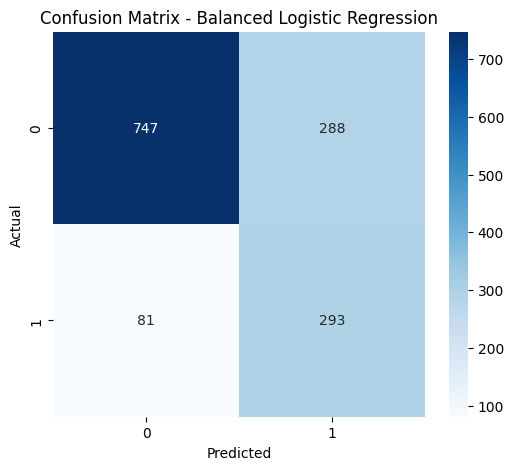

In [206]:
cm = confusion_matrix(
    y_test,
    logistic_balanced_pred
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Confusion Matrix - Balanced Logistic Regression")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

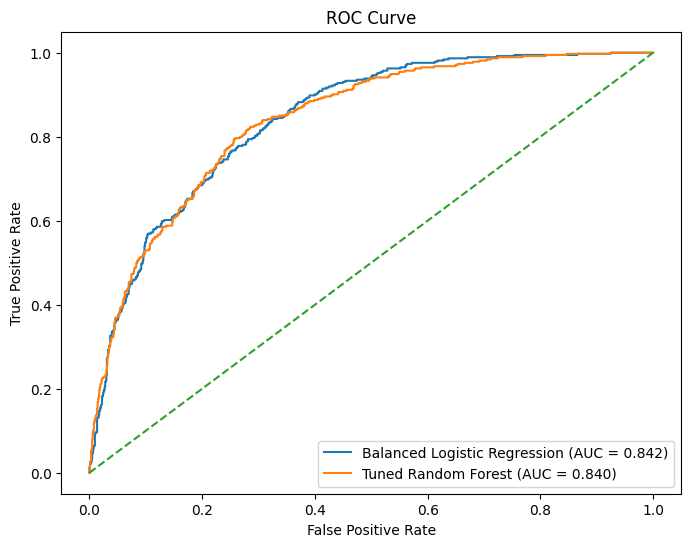

In [207]:
logistic_fpr, logistic_tpr, _ = roc_curve(
    y_test,
    logistic_balanced_probability
)

rf_fpr, rf_tpr, _ = roc_curve(
    y_test,
    tuned_rf_probability
)

plt.figure(figsize=(8, 6))

plt.plot(
    logistic_fpr,
    logistic_tpr,
    label=f"Balanced Logistic Regression (AUC = {logistic_balanced_auc:.3f})"
)

plt.plot(
    rf_fpr,
    rf_tpr,
    label=f"Tuned Random Forest (AUC = {tuned_rf_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")

plt.legend()
plt.show()

In [208]:
rf_classifier = tuned_rf.named_steps["classifier"]

feature_names = tuned_rf.named_steps[
    "preprocessor"
].get_feature_names_out()

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_classifier.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance.head(15)

,Feature,Importance
1,num__tenure,0.125993
36,cat__Contract_Month-to-month,0.120863
3,num__TotalCharges,0.100599
2,num__MonthlyCharges,0.073397
38,cat__Contract_Two year,0.063147
18,cat__OnlineSecurity_No,0.061089
16,cat__InternetService_Fiber optic,0.048780
27,cat__TechSupport_No,0.045835
43,cat__PaymentMethod_Electronic check,0.035284
37,cat__Contract_One year,0.019134


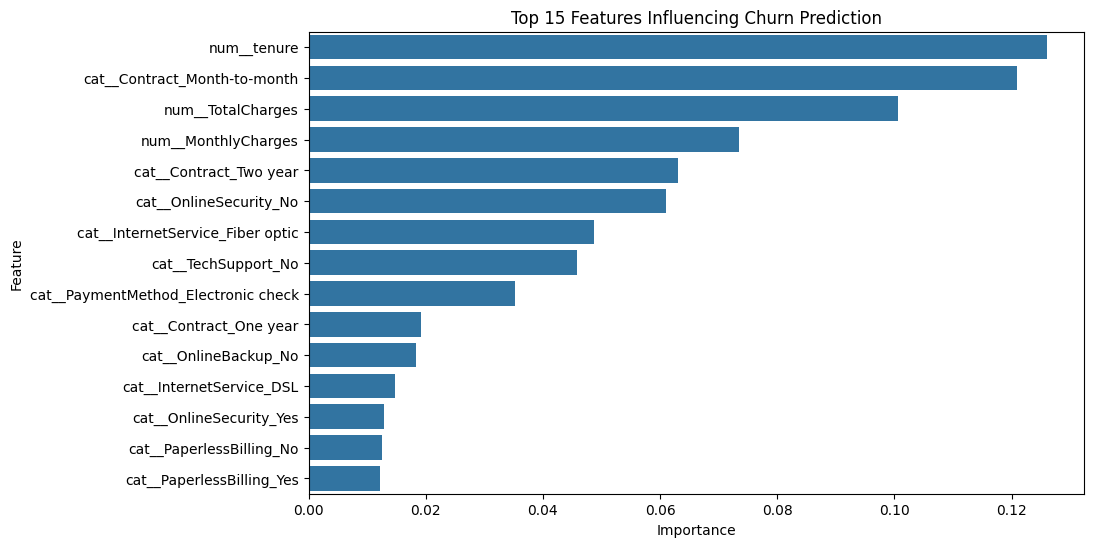

In [209]:
top_features = feature_importance.head(15)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Features Influencing Churn Prediction")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.show()

In [210]:
final_model = tuned_rf

print("Final Model: Tuned Random Forest")

Final Model: Tuned Random Forest


In [211]:
final_predictions = final_model.predict(X_test)

final_probabilities = final_model.predict_proba(X_test)[:, 1]

In [212]:
print("Predictions generated:", len(final_predictions))
print("Probabilities generated:", len(final_probabilities))

Predictions generated: 1409
Probabilities generated: 1409


In [213]:
def risk_level(probability):

    if probability < 0.30:
        return "Low"

    elif probability < 0.60:
        return "Medium"

    else:
        return "High"

In [214]:
risk_analysis = X_test.copy()

risk_analysis["customerID"] = df.loc[
    X_test.index,
    "customerID"
]

risk_analysis["Actual_Churn"] = y_test

risk_analysis["Predicted_Churn"] = final_predictions

risk_analysis["Churn_Probability"] = final_probabilities

risk_analysis["Risk_Level"] = [
    risk_level(prob)
    for prob in final_probabilities
]

In [215]:
risk_analysis.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,customerID,Actual_Churn,Predicted_Churn,Churn_Probability,Risk_Level
437,Male,0,Yes,Yes,72,Yes,Yes,Fiber optic,Yes,Yes,...,Two year,Yes,Credit card (automatic),114.05,8468.20,4376-KFVRS,0,0,0.019710,Low
2280,Female,1,No,No,8,Yes,Yes,Fiber optic,No,No,...,Month-to-month,Yes,Credit card (automatic),100.15,908.55,2754-SDJRD,0,1,0.809400,High
2235,Female,0,Yes,Yes,41,Yes,Yes,DSL,Yes,Yes,...,One year,Yes,Credit card (automatic),78.35,3211.20,9917-KWRBE,0,0,0.109672,Low
4460,Male,0,Yes,No,18,Yes,No,Fiber optic,No,No,...,Month-to-month,No,Electronic check,78.20,1468.75,0365-GXEZS,0,0,0.450338,Medium
3761,Female,0,Yes,No,72,Yes,Yes,DSL,Yes,Yes,...,Two year,Yes,Credit card (automatic),82.65,5919.35,9385-NXKDA,0,0,0.040223,Low


In [216]:
risk_analysis["Churn_Probability_Percent"] = (
    risk_analysis["Churn_Probability"] * 100
).round(2)

In [217]:
risk_analysis[
    [
        "customerID",
        "Churn_Probability_Percent",
        "Risk_Level"
    ]
].head(10)

,customerID,Churn_Probability_Percent,Risk_Level
437,4376-KFVRS,1.97,Low
2280,2754-SDJRD,80.94,High
2235,9917-KWRBE,10.97,Low
4460,0365-GXEZS,45.03,Medium
3761,9385-NXKDA,4.02,Low
5748,4686-UXDML,76.68,High
3568,2227-JRSJX,52.95,Medium
2976,4830-FAXFM,18.42,Low
5928,1830-IPXVJ,0.18,Low
1639,4690-LLKUA,59.37,Medium


In [218]:
risk_counts = risk_analysis["Risk_Level"].value_counts()

print(risk_counts)

Risk_Level
Low       704
High      392
Medium    313
Name: count, dtype: int64


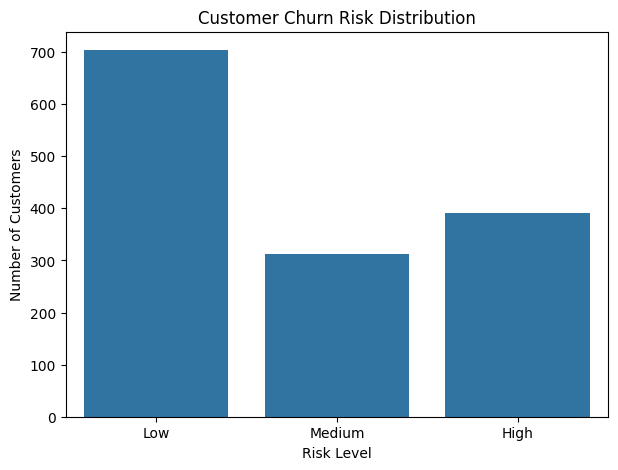

In [219]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=risk_analysis,
    x="Risk_Level",
    order=["Low", "Medium", "High"]
)

plt.title("Customer Churn Risk Distribution")
plt.xlabel("Risk Level")
plt.ylabel("Number of Customers")

plt.show()

In [220]:
risk_percentage = (
    risk_analysis["Risk_Level"]
    .value_counts(normalize=True)
    .reindex(["Low", "Medium", "High"])
    * 100
)

print(risk_percentage.round(2))

Risk_Level
Low       49.96
Medium    22.21
High      27.82
Name: proportion, dtype: float64


In [221]:
high_risk_customers = risk_analysis[
    risk_analysis["Risk_Level"] == "High"
].copy()

In [222]:
print(
    "High-risk customers:",
    len(high_risk_customers)
)

High-risk customers: 392


In [223]:
high_risk_customers[
    [
        "customerID",
        "tenure",
        "Contract",
        "InternetService",
        "MonthlyCharges",
        "PaymentMethod",
        "Churn_Probability_Percent",
        "Risk_Level"
    ]
].sort_values(
    by="Churn_Probability_Percent",
    ascending=False
).head(20)

,customerID,tenure,Contract,InternetService,MonthlyCharges,PaymentMethod,Churn_Probability_Percent,Risk_Level
6866,0295-PPHDO,1,Month-to-month,Fiber optic,95.45,Electronic check,94.76,High
4585,1069-XAIEM,1,Month-to-month,Fiber optic,85.05,Electronic check,94.39,High
3380,5178-LMXOP,1,Month-to-month,Fiber optic,95.10,Electronic check,94.20,High
3346,2545-EBUPK,2,Month-to-month,Fiber optic,84.05,Electronic check,93.11,High
2797,6023-YEBUP,3,Month-to-month,Fiber optic,100.95,Electronic check,93.03,High
2729,1143-NMNQJ,2,Month-to-month,Fiber optic,85.70,Electronic check,92.86,High
6623,9248-OJYKK,1,Month-to-month,Fiber optic,76.45,Electronic check,92.78,High
3727,9057-SIHCH,3,Month-to-month,Fiber optic,96.60,Electronic check,92.77,High
2194,2514-GINMM,1,Month-to-month,Fiber optic,79.50,Electronic check,92.17,High
2631,6861-XWTWQ,7,Month-to-month,Fiber optic,99.25,Electronic check,92.12,High


In [224]:
top_10_risk = risk_analysis.sort_values(
    by="Churn_Probability",
    ascending=False
).head(10)

top_10_risk[
    [
        "customerID",
        "tenure",
        "Contract",
        "InternetService",
        "MonthlyCharges",
        "TotalCharges",
        "PaymentMethod",
        "Churn_Probability_Percent",
        "Risk_Level"
    ]
]

,customerID,tenure,Contract,InternetService,MonthlyCharges,TotalCharges,PaymentMethod,Churn_Probability_Percent,Risk_Level
6866,0295-PPHDO,1,Month-to-month,Fiber optic,95.45,95.45,Electronic check,94.76,High
4585,1069-XAIEM,1,Month-to-month,Fiber optic,85.05,85.05,Electronic check,94.39,High
3380,5178-LMXOP,1,Month-to-month,Fiber optic,95.10,95.10,Electronic check,94.20,High
3346,2545-EBUPK,2,Month-to-month,Fiber optic,84.05,186.05,Electronic check,93.11,High
2797,6023-YEBUP,3,Month-to-month,Fiber optic,100.95,329.95,Electronic check,93.03,High
2729,1143-NMNQJ,2,Month-to-month,Fiber optic,85.70,169.80,Electronic check,92.86,High
6623,9248-OJYKK,1,Month-to-month,Fiber optic,76.45,76.45,Electronic check,92.78,High
3727,9057-SIHCH,3,Month-to-month,Fiber optic,96.60,291.90,Electronic check,92.77,High
2194,2514-GINMM,1,Month-to-month,Fiber optic,79.50,79.50,Electronic check,92.17,High
2631,6861-XWTWQ,7,Month-to-month,Fiber optic,99.25,665.45,Electronic check,92.12,High


In [225]:
def predict_customer_risk(customer_data):

    customer_features = customer_data.drop(
        columns=["Churn", "customerID"],
        errors="ignore"
    )

    prediction = final_model.predict(
        customer_features
    )[0]

    probability = final_model.predict_proba(
        customer_features
    )[0][1]

    risk = risk_level(probability)

    return {
        "Prediction": "Will Churn" if prediction == 1 else "Will Not Churn",
        "Churn Probability": round(probability * 100, 2),
        "Risk Level": risk
    }

In [226]:
customer = df.iloc[[0]].copy()

result = predict_customer_risk(customer)

result

{'Prediction': 'Will Churn',
 'Churn Probability': np.float64(59.96),
 'Risk Level': 'Medium'}

In [227]:
def analyze_customer(customer_index):

    customer = df.iloc[[customer_index]].copy()

    result = predict_customer_risk(customer)

    print("Customer ID:", customer["customerID"].iloc[0])
    print("Prediction:", result["Prediction"])
    print("Churn Probability:", result["Churn Probability"], "%")
    print("Risk Level:", result["Risk Level"])

In [228]:
analyze_customer(0)

Customer ID: 7590-VHVEG
Prediction: Will Churn
Churn Probability: 59.96 %
Risk Level: Medium


In [229]:
contract_risk = pd.crosstab(
    risk_analysis["Contract"],
    risk_analysis["Risk_Level"],
    normalize="index"
) * 100

contract_risk.round(2)

Risk_Level,High,Low,Medium
Contract,,,
Month-to-month,50.71,17.21,32.08
One year,0.00,80.67,19.33
Two year,0.00,97.92,2.08


In [230]:
internet_risk = pd.crosstab(
    risk_analysis["InternetService"],
    risk_analysis["Risk_Level"],
    normalize="index"
) * 100

internet_risk.round(2)

Risk_Level,High,Low,Medium
InternetService,,,
DSL,14.26,59.71,26.03
Fiber optic,51.55,23.33,25.12
No,2.24,87.18,10.58


In [231]:
payment_risk = pd.crosstab(
    risk_analysis["PaymentMethod"],
    risk_analysis["Risk_Level"],
    normalize="index"
) * 100

payment_risk.round(2)

Risk_Level,High,Low,Medium
PaymentMethod,,,
Bank transfer (automatic),11.33,67.33,21.33
Credit card (automatic),12.94,66.99,20.06
Electronic check,55.06,21.10,23.84
Mailed check,17.48,59.82,22.70


In [232]:
risk_analysis.to_csv(
    "customer_churn_risk_analysis.csv",
    index=False
)

In [233]:
print("Risk analysis file saved successfully.")

Risk analysis file saved successfully.


In [234]:
from google.colab import files

files.download(
    "customer_churn_risk_analysis.csv"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [235]:
import joblib

joblib.dump(
    final_model,
    "churn_prediction_model.pkl"
)

print("Final model saved successfully.")

Final model saved successfully.


In [236]:
feature_importance.to_csv(
    "churn_feature_importance.csv",
    index=False
)

print("Feature importance saved successfully.")

Feature importance saved successfully.


In [237]:
final_accuracy = accuracy_score(
    y_test,
    final_predictions
)

final_precision = precision_score(
    y_test,
    final_predictions
)

final_recall = recall_score(
    y_test,
    final_predictions
)

final_f1 = f1_score(
    y_test,
    final_predictions
)

final_auc = roc_auc_score(
    y_test,
    final_probabilities
)

print("FINAL MODEL PERFORMANCE")
print("-----------------------")
print("Model     : Tuned Random Forest")
print("Accuracy  :", round(final_accuracy, 4))
print("Precision :", round(final_precision, 4))
print("Recall    :", round(final_recall, 4))
print("F1 Score  :", round(final_f1, 4))
print("ROC-AUC   :", round(final_auc, 4))

FINAL MODEL PERFORMANCE
-----------------------
Model     : Tuned Random Forest
Accuracy  : 0.7658
Precision : 0.5445
Recall    : 0.7193
F1 Score  : 0.6198
ROC-AUC   : 0.8396


In [240]:
best_model = tuned_rf

In [241]:
y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:, 1]

In [242]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

print("Final Tuned Random Forest Results")
print("----------------------------------")
print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1 Score  : {f1:.4f}")
print(f"ROC-AUC   : {roc_auc:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Final Tuned Random Forest Results
----------------------------------
Accuracy  : 0.7658
Precision : 0.5445
Recall    : 0.7193
F1 Score  : 0.6198
ROC-AUC   : 0.8396

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.78      0.83      1035
           1       0.54      0.72      0.62       374

    accuracy                           0.77      1409
   macro avg       0.71      0.75      0.73      1409
weighted avg       0.79      0.77      0.77      1409



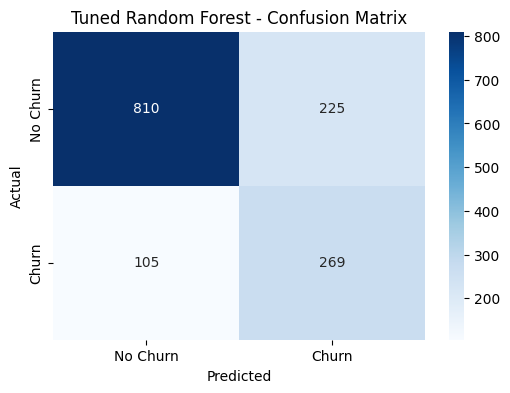

In [243]:
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Tuned Random Forest - Confusion Matrix")
plt.show()

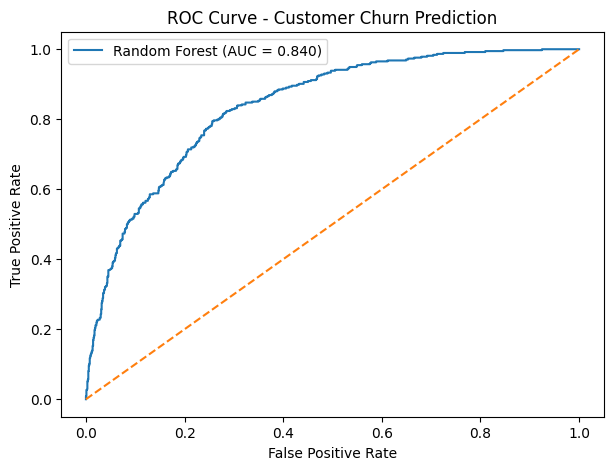

In [244]:
from sklearn.metrics import roc_curve, auc

fpr, tpr, thresholds = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"Random Forest (AUC = {roc_auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Customer Churn Prediction")
plt.legend()
plt.show()

In [247]:
importance = pd.Series(
    rf_model.feature_importances_,
    index=feature_names
).sort_values(ascending=False)

print(importance.head(10))

num__tenure                            0.125993
cat__Contract_Month-to-month           0.120863
num__TotalCharges                      0.100599
num__MonthlyCharges                    0.073397
cat__Contract_Two year                 0.063147
cat__OnlineSecurity_No                 0.061089
cat__InternetService_Fiber optic       0.048780
cat__TechSupport_No                    0.045835
cat__PaymentMethod_Electronic check    0.035284
cat__Contract_One year                 0.019134
dtype: float64


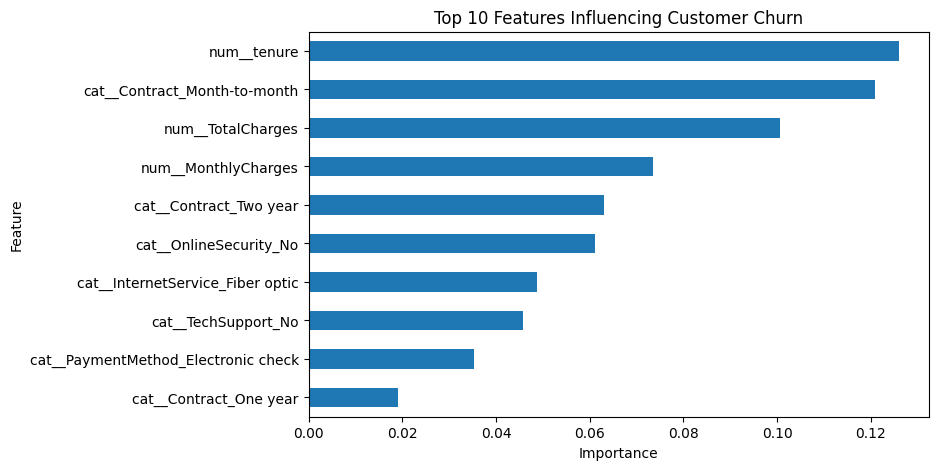

In [248]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

importance.head(10).sort_values().plot(kind="barh")

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 10 Features Influencing Customer Churn")

plt.show()

In [249]:
feature_names = preprocessor.get_feature_names_out()